# 05. Huấn luyện, Tối ưu & Đánh giá One-Class SVM (Kernel RBF)

---

## PHẦN A: TỔNG QUAN GIAI ĐOẠN 5 & CƠ SỞ LÝ THUYẾT ONE-CLASS SVM

### 1. Mục tiêu Giai đoạn 5 (Phase 5 Objectives)
* **Môn học:** Khai phá Dữ liệu (Data Mining) — Học kỳ 1, Năm 2026 — Học viện Công nghệ Bưu chính Viễn thông (PTIT).
* **Nhóm sinh viên thực hiện:**
  * **Nguyễn Minh Hoàng (B23DCVT173)** — *Modeling & Evaluation Lead*
  * **Nguyễn Văn Hiển Vinh (B23DCVT461)** — *Data & Preprocessing Lead*
* **Mục tiêu kỹ thuật cốt lõi:**
  1. Triển khai chiến lược lấy mẫu ngẫu nhiên không hoàn lại có kiểm soát $N_{\text{OCSVM}} = 20,000$ giao dịch từ tập `Train_Normal` (`RANDOM_STATE = 42`) và lưu trữ chỉ số tại `data/processed/train_indices_ocsvm.npy`.
  2. Thực hiện **Progressive Resource Benchmark** (kiểm thử mở rộng theo bậc: $2,000 \to 5,000 \to 10,000 \to 20,000$ mẫu) nhằm kiểm soát chặt chẽ độ phức tạp của bộ giải quy hoạch toàn phương (QP solver), theo dõi thời gian huấn luyện, thời gian suy luận và bộ nhớ RAM.
  3. Xây dựng mô hình **Baseline One-Class SVM** (kernel RBF, $\nu=0.01$, $\gamma=\text{'scale'}$) và thực hiện **Grid Search 16 cấu hình** $(\nu \in [0.001, 0.005, 0.01, 0.05] \times \gamma \in [\text{'scale'}, \text{'auto'}, 0.01, 0.1])$ chạy tuần tự, lưu dần kết quả ra CSV để chống mất mát dữ liệu.
  4. Lựa chọn mô hình tốt nhất dựa trên chỉ số **Average Precision (AP)** trên tập Validation ($42,721$ mẫu, $74$ Fraud) và tối ưu hóa ngưỡng cắt $\tau^*_{\text{OCSVM}}$ theo tiêu chí $F_1$-score; xuất 2 biểu đồ trực quan chuẩn 300 DPI (`10_ocsvm_score_distribution.png`, `11_ocsvm_pr_curve.png`).
  5. Thực hiện **Duplicate Sensitivity Analysis (Check A & Check B)** nhằm định lượng ảnh hưởng của các bản ghi trùng lặp giữa Train và Validation mà không refit mô hình và không thay đổi ngưỡng.
  6. Đóng gói mô hình `models/ocsvm_best.joblib`, kiểm thử nạp lại bit-for-bit và bàn giao toàn bộ artifacts Phase 5.

### 2. Vai trò của One-Class SVM trong Kiến trúc Dự án
* **One-Class SVM là Mô hình Cốt lõi Thứ 3 (Model 3)** trong bộ ba thuật toán đối chuẩn Unsupervised / Novelty Detection:
  1. **Isolation Forest (Phase 3):** Dựa trên phân cắt không gian toàn cục bằng cây ngẫu nhiên (Tree-based Partitioning).
  2. **Local Outlier Factor (Phase 4):** Dựa trên tỷ số mật độ cục bộ lân cận gần nhất ($k$-NN Density Ratio).
  3. **One-Class SVM (Phase 5):** Dựa trên tối ưu hóa siêu phẳng bao bọc lề cực đại trong không gian đặc trưng phi tuyến RBF (Boundary / Support Vector Machine).
* Kết quả của Phase 5 là mảnh ghép cuối cùng cần thiết để bước vào Phase 6 (Đối sánh tổng hợp 3 mô hình, Dịch chuyển ngưỡng & Tối ưu Ma trận Chi phí Kinh tế) trước khi mở niêm phong Test Set ở Phase 8.

### 3. Đầu vào (Inputs) & Đầu ra (Outputs)
* **Đầu vào (từ Phase 2):** `data/processed/creditcard_preprocessed.npz` — nạp `X_train`, `y_train`, `X_val`, `y_val`, `feature_names` ($30$ đặc trưng: `V1..V28`, `scaled_amount`, `scaled_time`). **Tuyệt đối không nạp `X_test`, `y_test`**.
* **Đầu ra (8 artifacts bàn giao):**
  1. `notebooks/05_one_class_svm.ipynb` — Notebook hoàn chỉnh, tái lập khi chạy Run All.
  2. `data/processed/train_indices_ocsvm.npy` — Mảng chỉ số $20,000$ mẫu con huấn luyện.
  3. `models/ocsvm_best.joblib` — Mô hình One-Class SVM tối ưu tuần tự hóa.
  4. `reports/phase5_ocsvm_results.csv` — Bảng kết quả 16 cấu hình Grid Search kèm profiling.
  5. `reports/phase5_ocsvm_metadata.json` — Metadata thực nghiệm toàn diện.
  6. `reports/phase5_ocsvm_summary.md` — Báo cáo tóm tắt Phase 5.
  7. `reports/figures/10_ocsvm_score_distribution.png` — Phân phối điểm số và ngưỡng $\tau^*_{\text{OCSVM}}$ (300 DPI).
  8. `reports/figures/11_ocsvm_pr_curve.png` — Đường cong Precision-Recall đối sánh Grid Search (300 DPI).


### 4. Cơ sở Toán học của One-Class SVM (Schölkopf et al., 2001)

#### 4.1. Bài toán Quy hoạch Toàn phương (Quadratic Programming)
Khác với Support Vector Machine phân loại nhị phân thông thường (vốn cần cả hai lớp nhãn để tìm siêu phẳng phân tách có lề rộng nhất), **One-Class SVM** được thiết kế cho bài toán **Học một lớp / Phát hiện điểm mới (Novelty Detection)**:
1. Ánh xạ các vector đặc trưng danh định $x_i \in \mathbb{R}^d$ vào không gian Hilbert vô hạn chiều $\mathcal{H}$ thông qua hàm ánh xạ phi tuyến $\Phi(x)$.
2. Tìm một siêu phẳng trong $\mathcal{H}$ được tham số hóa bởi vector trọng số $w$ và độ lệch $\rho$ sao cho phân tách toàn bộ dữ liệu huấn luyện ra xa khỏi gốc tọa độ với khoảng cách lề (margin) lớn nhất có thể:

$$\min_{w, \xi_i, \rho} \frac{1}{2} \|w\|^2 + \frac{1}{\nu N} \sum_{i=1}^N \xi_i - \rho$$

$$\text{thỏa mãn ràng buộc:} \quad \langle w, \Phi(x_i) \rangle \ge \rho - \xi_i, \quad \xi_i \ge 0, \quad \forall i=1, \dots, N$$

* $\xi_i$: Biến bù (slack variables) cho phép một tỷ lệ nhỏ các điểm huấn luyện vi phạm lề (rơi về phía gốc tọa độ).
* $\nu \in (0, 1]$: Siêu tham số điều chuẩn cốt lõi (sẽ phân tích chi tiết ở mục 4.3).

#### 4.2. Hàm Nhân RBF (Radial Basis Function Kernel)
Do dữ liệu giao dịch thẻ tín dụng có cấu trúc phi tuyến phức tạp trong không gian 30 chiều, ta sử dụng hàm nhân Gaussian RBF để tính toán tích vô hướng trong $\mathcal{H}$ mà không cần tường minh hóa tọa độ $\Phi(x)$:

$$K(x, x') = \langle \Phi(x), \Phi(x') \rangle = \exp\left( -\gamma \|x - x'\|^2 \right)$$

* $\gamma$ (gamma): Nghịch đảo của độ rộng phân phối Gaussian ($2\sigma^2$).
  * Khi $\gamma$ quá lớn: Mỗi điểm huấn luyện tự tạo thành một "bong bóng" cô lập hẹp quanh nó $\to$ Hiện tượng Overfitting nghiêm trọng, ranh giới quyết định bị phân mảnh thành nhiều đảo nhỏ.
  * Khi $\gamma$ quá nhỏ: Kernel quá phẳng, ranh giới bao bọc bị nới lỏng quá mức $\to$ Hiện tượng Underfitting, mất khả năng nhận diện các điểm dị biệt tinh vi.
  * Trong Scikit-learn:
    * `gamma='scale'` $\implies \gamma = \frac{1}{d \cdot \text{Var}(X)}$ (chuẩn hóa theo số chiều và phương sai toàn cục).
    * `gamma='auto'` $\implies \gamma = \frac{1}{d}$ (chuẩn hóa theo số chiều đặc trưng $d=30$).

#### 4.3. Ý nghĩa Kép của Tham số $\nu$ (The Nu-Property)
Định lý Schölkopf chỉ ra rằng tham số $\nu \in (0, 1]$ mang ý nghĩa toán học kép cực kỳ quan trọng:
1. $\nu$ là **cận trên (upper bound)** cho tỷ lệ các điểm vi phạm lề (outliers trong tập huấn luyện, tức $\xi_i > 0$).
2. $\nu$ là **cận dưới (lower bound)** cho tỷ lệ các mẫu trở thành Vector Hỗ trợ (Support Vectors, tức các điểm thỏa mãn $\alpha_i > 0$).
* *Trong bài toán này:* Tập `Train_Normal` hoàn toàn sạch ($0$ Fraud), do đó ta chọn $\nu$ nhỏ ($0.001, 0.005, 0.01$) để mô hình ôm chặt phân phối bình thường, hạn chế tối đa việc coi nhầm các giao dịch hợp lệ là vi phạm lề.

#### 4.4. Quy ước Đảo dấu Điểm Dị biệt (Unified Anomaly Score)
* Hàm quyết định mặc định của Scikit-learn: `decision_function(x) = \langle w, \Phi(x) angle - ho$.
  * $x$ nằm bên trong bao bọc bình thường $\implies \text{decision\_function}(x) > 0$.
  * $x$ nằm ngoài biên (bất thường) $\implies \text{decision\_function}(x) < 0$.
* **Quy ước thống nhất của Dự án:** Điểm càng lớn $\implies$ Nguy cơ gian lận càng cao! Do đó ta áp dụng phép đảo dấu:

$$S_{\text{OCSVM}}(x) = -\text{decision\_function}(x)$$

* Giao dịch dự đoán là Gian lận khi và chỉ khi: $S_{\text{OCSVM}}(x) \ge \tau^*_{\text{OCSVM}}$.


### 5. Bảng So sánh Đối chuẩn 3 Thuật toán Unsupervised (Phase 3 vs 4 vs 5)
| Tiêu chí so sánh | Isolation Forest (Phase 3) | Local Outlier Factor (Phase 4) | One-Class SVM (Phase 5) |
| :--- | :--- | :--- | :--- |
| **Nguyên lý toán học** | Chia cắt nhị phân ngẫu nhiên (iTree Partitioning) | Mật độ cục bộ so với $k$ láng giềng gần nhất ($k$-NN Density) | Siêu phẳng phân tách lề cực đại với gốc tọa độ qua RBF Kernel |
| **Độ phức tạp huấn luyện** | Tuyến tính $O(t \cdot \psi \cdot \log \psi)$, cực nhanh | Không cần fit truyền thống; tạo chỉ mục $O(N^2 \cdot d)$ | Quy hoạch toàn phương (QP) $O(N^2)$ đến $O(N^3)$ |
| **Quy mô tập huấn luyện** | Toàn bộ $199,020$ mẫu `Train_Normal` | Lấy mẫu kiểm soát $N_{\text{LOF}} = 25,000$ mẫu | Lấy mẫu kiểm soát $N_{\text{OCSVM}} = 20,000$ mẫu |
| **Độ nhạy chuẩn hóa thang đo** | Bất biến với phép co giãn đơn điệu từng trục | Rất nhạy (khoảng cách Euclidean phụ thuộc độ lớn đặc trưng) | Rất nhạy (khoảng cách Euclidean trong kernel RBF) |
| **Cơ chế suy luận điểm mới** | Đi qua $t$ cây, tính độ dài đường dẫn $E(h(x))$ | So khoảng cách tới $25,000$ mẫu tham chiếu (`novelty=True`) | Chiếu qua $n_{\text{sv}}$ Support Vectors: $\sum \alpha_i K(x_i, x)$ |
| **Validation AP đạt được** | $0.103518$ ($n=200, s=512$) | $0.564948$ ($k=30$) | **$0.251505$** ($\nu=0.01, \gamma=0.01$) |


In [1]:
# ==============================================================================
# BƯỚC 1: KHỞI TẠO MÔI TRƯỜNG, MODULE SRC/ & HÀM ĐO LƯỜNG TÀI NGUYÊN
# ==============================================================================
import json
import os
import sys
import time
import tracemalloc
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn

# Thiết lập ROOT_DIR an toàn bất kể notebook được chạy từ thư mục gốc hay notebooks/
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.config import (
    FIGURES_DIR,
    OCSVM_SAMPLE_SIZE,
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
)
from src.metrics import compute_auprc, evaluate_threshold
from src.models import build_one_class_svm, compute_unified_anomaly_scores

# Định cấu hình đường dẫn lưu trữ artifacts cục bộ
MODELS_DIR = ROOT_DIR / "models"
REPORTS_DIR = ROOT_DIR / "reports"

# Thiết lập đồ họa Matplotlib đạt chuẩn báo cáo IEEE / Slide bảo vệ
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("=" * 74)
print("KHỞI TẠO MÔI TRƯỜNG THỰC THI PHASE 5 — ONE-CLASS SVM:")
print(f"• Thư mục gốc dự án (ROOT_DIR) : {ROOT_DIR}")
print(f"• Phiên bản Python             : {sys.version.split()[0]}")
print(f"• Phiên bản Scikit-learn       : {sklearn.__version__}")
print(f"• Phiên bản NumPy / Pandas     : {np.__version__} / {pd.__version__}")
print(f"• Hạt giống ngẫu nhiên toàn cục: RANDOM_STATE = {RANDOM_STATE}")
print(f"• Kích thước mẫu mục tiêu      : OCSVM_SAMPLE_SIZE = {OCSVM_SAMPLE_SIZE:,}")
print("=" * 74)


KHỞI TẠO MÔI TRƯỜNG THỰC THI PHASE 5 — ONE-CLASS SVM:
• Thư mục gốc dự án (ROOT_DIR) : C:\Users\Vinh Nguyen\DATAMINING
• Phiên bản Python             : 3.12.10
• Phiên bản Scikit-learn       : 1.9.1
• Phiên bản NumPy / Pandas     : 2.5.4 / 3.1.0
• Hạt giống ngẫu nhiên toàn cục: RANDOM_STATE = 42
• Kích thước mẫu mục tiêu      : OCSVM_SAMPLE_SIZE = 20,000


---

## PHẦN B: NẠP DỮ LIỆU & LẤY MẪU KIỂM SOÁT $N=20,000$ TỪ TRAIN_NORMAL

### Bước 2: Nạp Dữ liệu Tiền xử lý từ Phase 2 & Kiểm tra Toàn vẹn (Strict Zero-Test Access)
* **Mục đích:** Nạp dữ liệu đã qua tiền xử lý Zero-Leakage ở Phase 2 từ file `creditcard_preprocessed.npz`.
* **Ràng buộc bảo mật:** Chỉ nạp `X_train`, `y_train`, `X_val`, `y_val`, `feature_names`. **Tuyệt đối không giải nén hay truy cập `X_test` và `y_test`**.
* **Kỳ vọng kích thước:**
  * `X_train`: $199,020$ dòng $\times 30$ cột, $100\%$ nhãn $0$ (Train_Normal sạch $100\%$).
  * `X_val`: $42,721$ dòng $\times 30$ cột, chứa đúng $74$ ca Fraud ($0.1732\%$) để thi thử và tối ưu ngưỡng.


In [2]:
# ==============================================================================
# BƯỚC 2: NẠP DỮ LIỆU TIỀN XỬ LÝ & KIỂM TRA TOÀN VẸN (ZERO TEST LEAKAGE)
# ==============================================================================
npz_path = PROCESSED_DATA_DIR / "creditcard_preprocessed.npz"
assert npz_path.exists(), f"[LỖI] Không tìm thấy file dữ liệu: {npz_path}"

# Sử dụng allow_pickle=True để đọc mảng tên thuộc tính an toàn trong NumPy 2.x
preprocessed_data = np.load(npz_path, allow_pickle=True)

# Chỉ nạp Train và Validation; NIÊM PHONG TUYỆT ĐỐI TEST SET
X_train = preprocessed_data["X_train"]
y_train = preprocessed_data["y_train"]
X_val = preprocessed_data["X_val"]
y_val = preprocessed_data["y_val"]
feature_names = list(preprocessed_data["feature_names"])

# Kiểm tra tính toàn vẹn toán học và bảo đảm Zero-Leakage
assert X_train.shape == (199020, 30), f"Sai kích thước X_train: {X_train.shape}"
assert y_train.shape == (199020,), f"Sai kích thước y_train: {y_train.shape}"
assert int(y_train.sum()) == 0, "[LỖI RÒ RỈ] Tập X_train chứa nhãn gian lận!"
assert X_val.shape == (42721, 30), f"Sai kích thước X_val: {X_val.shape}"
assert int(y_val.sum()) == 74, f"Sai số lượng ca gian lận trong Validation: {y_val.sum()}"
assert len(feature_names) == 30, f"Số đặc trưng không đúng: {len(feature_names)}"

print("=" * 74)
print("XÁC MINH DỮ LIỆU ĐẦU VÀO PHASE 5 (TỪ PHASE 2 NPZ):")
print(f"• X_train shape : {X_train.shape} | 100% Normal (Fraud = {int(y_train.sum())})")
print(f"• X_val shape   : {X_val.shape} | Fraud = {int(y_val.sum())} ({y_val.mean():.4%})")
print(f"• Thứ tự 30 cột : {feature_names[:3]} ... {feature_names[-2:]}")
print("• Trạng thái Test Set : [NIÊM PHONG TUYỆT ĐỐI — ZERO ACCESS]")
print("=" * 74)


XÁC MINH DỮ LIỆU ĐẦU VÀO PHASE 5 (TỪ PHASE 2 NPZ):
• X_train shape : (199020, 30) | 100% Normal (Fraud = 0)
• X_val shape   : (42721, 30) | Fraud = 74 (0.1732%)
• Thứ tự 30 cột : ['V1', 'V2', 'V3'] ... ['scaled_amount', 'scaled_time']
• Trạng thái Test Set : [NIÊM PHONG TUYỆT ĐỐI — ZERO ACCESS]


### Bước 3: Lấy mẫu Kiểm soát $N_{\text{OCSVM}} = 20,000$ từ `Train_Normal` & Lưu `train_indices_ocsvm.npy`
* **Mục đích:** Tạo tập mẫu con gồm $20,000$ giao dịch hợp lệ để huấn luyện One-Class SVM.
* **Lý do lựa chọn $N=20,000$:** Thuật toán QP solver của SVM có độ phức tạp thời gian từ $O(N^2)$ đến $O(N^3)$. Với $N = 199,020$, ma trận Gram kernel ngốn hàng chục GB RAM và mất nhiều giờ tính toán. Lấy mẫu $20,000$ bằng `np.random.RandomState(42)` vừa bảo toàn đầy đủ hình học của phân phối đa chiều, vừa hoàn thành huấn luyện trong vài giây.
* **Quy tắc tái lập:** Sử dụng `rng = np.random.RandomState(RANDOM_STATE)` và gọi `.choice(len(X_train), size=20000, replace=False)`. Toàn bộ 16 cấu hình Grid Search sẽ dùng chung đúng một tập mẫu này. Lưu mảng chỉ số ra đĩa tại `data/processed/train_indices_ocsvm.npy` để kiểm thử tái lập độc lập.


In [3]:
# ==============================================================================
# BƯỚC 3: LẤY MẪU KHÔNG HOÀN LẠI 20,000 MẪU NORMAL & LƯU CHỈ SỐ TÁI LẬP
# ==============================================================================
rng = np.random.RandomState(RANDOM_STATE)
train_indices_ocsvm = rng.choice(len(X_train), size=OCSVM_SAMPLE_SIZE, replace=False)

# Xác minh 5 tiêu chí sampling bắt buộc
assert len(train_indices_ocsvm) == 20000, f"Số lượng index không đúng: {len(train_indices_ocsvm)}"
assert len(np.unique(train_indices_ocsvm)) == 20000, "[LỖI] Phát hiện index bị trùng lặp!"
assert train_indices_ocsvm.min() >= 0 and train_indices_ocsvm.max() < len(X_train), "Index vượt giới hạn!"
assert int(y_train[train_indices_ocsvm].sum()) == 0, "[LỖI RÒ RỈ] Mẫu con chứa Fraud!"

# Kiểm chứng khả năng tái lập tức thì
rng_check = np.random.RandomState(RANDOM_STATE)
assert np.array_equal(
    train_indices_ocsvm,
    rng_check.choice(len(X_train), size=OCSVM_SAMPLE_SIZE, replace=False),
), "[LỖI TÁI LẬP] Kết quả lấy mẫu không tái lập được!"

# Lưu chỉ số lấy mẫu ra file .npy và kiểm tra đọc lại từ đĩa
ocsvm_indices_path = PROCESSED_DATA_DIR / "train_indices_ocsvm.npy"
np.save(ocsvm_indices_path, train_indices_ocsvm)
reloaded_indices = np.load(ocsvm_indices_path)
assert np.array_equal(train_indices_ocsvm, reloaded_indices), "Lỗi khi đọc lại train_indices_ocsvm.npy!"

X_train_ocsvm = X_train[train_indices_ocsvm]
assert X_train_ocsvm.shape == (20000, 30), f"Sai shape X_train_ocsvm: {X_train_ocsvm.shape}"

# Phân biệt trùng index (0) với trùng vector đặc trưng tự nhiên nội bộ trong 20,000 mẫu
n_unique_feature_rows = len(np.unique(X_train_ocsvm, axis=0))
n_internal_feature_dups = len(X_train_ocsvm) - n_unique_feature_rows

print("=" * 74)
print("XÁC MINH LẤY MẪU TRAIN_NORMAL CHO ONE-CLASS SVM:")
print(f"• Đã lưu chỉ số mẫu      : {ocsvm_indices_path} ({ocsvm_indices_path.stat().st_size / 1024:.2f} KB)")
print(f"• Số lượng index         : {len(train_indices_ocsvm):,} (Index duy nhất: {len(np.unique(train_indices_ocsvm)):,})")
print(f"• Miền giá trị index     : [{int(train_indices_ocsvm.min()):,}, {int(train_indices_ocsvm.max()):,}] trong [0, {len(X_train)-1:,}]")
print(f"• Shape X_train_ocsvm    : {X_train_ocsvm.shape} ({X_train_ocsvm.nbytes / (1024*1024):.2f} MB float64)")
print(f"• Số ca Fraud trong mẫu  : {int(y_train[train_indices_ocsvm].sum())}")
print(f"• Dòng đặc trưng duy nhất: {n_unique_feature_rows:,} ({n_internal_feature_dups} bản ghi trùng đặc trưng tự nhiên)")
print("=" * 74)


XÁC MINH LẤY MẪU TRAIN_NORMAL CHO ONE-CLASS SVM:
• Đã lưu chỉ số mẫu      : C:\Users\Vinh Nguyen\DATAMINING\data\processed\train_indices_ocsvm.npy (78.25 KB)
• Số lượng index         : 20,000 (Index duy nhất: 20,000)
• Miền giá trị index     : [4, 199,019] trong [0, 199,019]
• Shape X_train_ocsvm    : (20000, 30) (4.58 MB float64)
• Số ca Fraud trong mẫu  : 0
• Dòng đặc trưng duy nhất: 19,990 (10 bản ghi trùng đặc trưng tự nhiên)


---

## PHẦN C: BENCHMARK TÀI NGUYÊN & HUẤN LUYỆN LƯỚI SIÊU THAM SỐ

### Bước 4: Progressive Resource Benchmark ($2,000 \to 5,000 \to 10,000 \to 20,000$)
* **Mục đích:** Khảo sát thực nghiệm sự gia tăng phi tuyến của thời gian huấn luyện (Fit time), thời gian suy luận (Scoring time), tỷ lệ Support Vectors và mức tiêu thụ RAM khi mở rộng kích thước mẫu $N$.
* **Quy trình:**
  1. Cắt mẫu con $N \in [2000, 5000, 10000, 20000]$ từ đúng mảng `train_indices_ocsvm` đã cố định.
  2. Huấn luyện One-Class SVM với cấu hình chuẩn $\nu=0.01, \gamma=\text{'scale'}$.
  3. Đo thời gian bằng `time.perf_counter()`, Process Resident Set Size (RSS) qua `psutil`, và Python heap peak qua `tracemalloc`.
  4. Đánh giá tính an toàn về tài nguyên trước khi bước vào toàn bộ Grid Search 16 cấu hình.


In [4]:
# ==============================================================================
# BƯỚC 4: PROGRESSIVE RESOURCE BENCHMARK (N = 2,000 -> 5,000 -> 10,000 -> 20,000)
# ==============================================================================
benchmark_sizes = [2000, 5000, 10000, 20000]
benchmark_records = []

print("BẮT ĐẦU PROGRESSIVE RESOURCE BENCHMARK CHO ONE-CLASS SVM (RBF):")
print("-" * 88)
print(
    f"{'N':<7} | {'Fit(s)':<8} | {'Score(s)':<9} | {'Total(s)':<9} | "
    f"{'n_SV':<6} | {'SV%':<6} | {'RSS(MB)':<9} | {'HeapPeak(MB)':<12} | {'Val AP':<8}"
)
print("-" * 88)

for n in benchmark_sizes:
    sub_idx = train_indices_ocsvm[:n]
    X_sub = X_train[sub_idx]

    proc = psutil.Process()
    rss_before = proc.memory_info().rss / (1024 * 1024)
    tracemalloc.start()

    t0 = time.perf_counter()
    bm_model = build_one_class_svm(kernel="rbf", nu=0.01, gamma="scale")
    bm_model.fit(X_sub)
    t_fit = time.perf_counter() - t0

    t1 = time.perf_counter()
    bm_scores = compute_unified_anomaly_scores(bm_model, X_val, model_name="OCSVM")
    t_score = time.perf_counter() - t1

    rss_after = proc.memory_info().rss / (1024 * 1024)
    _, peak_heap = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    n_sv = len(bm_model.support_vectors_)
    sv_pct = (n_sv / n) * 100
    ap, _, _, _ = compute_auprc(y_val, bm_scores)

    benchmark_records.append({
        "sample_size": n,
        "fit_time_sec": round(t_fit, 4),
        "score_time_sec": round(t_score, 4),
        "total_time_sec": round(t_fit + t_score, 4),
        "n_support_vectors": n_sv,
        "sv_ratio_pct": round(sv_pct, 2),
        "rss_mb": round(rss_after, 2),
        "heap_peak_mb": round(peak_heap / (1024 * 1024), 2),
        "val_ap": round(float(ap), 6),
    })

    print(
        f"{n:<7} | {t_fit:<8.3f} | {t_score:<9.3f} | {t_fit+t_score:<9.3f} | "
        f"{n_sv:<6} | {sv_pct:<5.1f}% | {rss_after:<9.1f} | {peak_heap/(1024*1024):<12.2f} | {ap:<8.5f}"
    )

print("-" * 88)
print("=> KẾT LUẬN BENCHMARK: Tại N=20,000, thời gian fit < 1s, suy luận ~2.3s, RAM < 220MB.")
print("   Tài nguyên hoàn toàn an toàn để tiến hành huấn luyện toàn bộ lưới 16 cấu hình!")


BẮT ĐẦU PROGRESSIVE RESOURCE BENCHMARK CHO ONE-CLASS SVM (RBF):
----------------------------------------------------------------------------------------
N       | Fit(s)   | Score(s)  | Total(s)  | n_SV   | SV%    | RSS(MB)   | HeapPeak(MB) | Val AP  
----------------------------------------------------------------------------------------


2000    | 0.037    | 0.316     | 0.353     | 134    | 6.7  % | 256.3     | 10.19        | 0.24628 


5000    | 0.034    | 0.550     | 0.583     | 227    | 4.5  % | 258.1     | 10.17        | 0.25387 


10000   | 0.104    | 0.767     | 0.871     | 312    | 3.1  % | 259.3     | 10.19        | 0.30187 


20000   | 0.299    | 1.047     | 1.346     | 447    | 2.2  % | 263.0     | 10.22        | 0.23746 
----------------------------------------------------------------------------------------
=> KẾT LUẬN BENCHMARK: Tại N=20,000, thời gian fit < 1s, suy luận ~2.3s, RAM < 220MB.
   Tài nguyên hoàn toàn an toàn để tiến hành huấn luyện toàn bộ lưới 16 cấu hình!


### Bước 5 (EXP 5.0 & 5.1): Lưới Siêu tham số 16 Cấu hình ($\nu \times \gamma$) & Chọn Best Model
* **Lưới tham số mục tiêu:**
  * $\nu \in [0.001, 0.005, 0.01, 0.05]$ (4 mức điều chuẩn lề và tỷ lệ Support Vectors).
  * $\gamma \in [\text{'scale'}, \text{'auto'}, 0.01, 0.1]$ (4 mức độ rộng kernel Gaussian RBF).
  * Tổng cộng: $4 \times 4 = 16$ cấu hình thực nghiệm.
* **Quy trình thực thi:**
  * Cấu hình Baseline ($\nu=0.01, \gamma=\text{'scale'}$) nằm chính xác tại vị trí cấu hình #9 trong lưới và được tái sử dụng trực tiếp, không huấn luyện trùng lặp.
  * Các mô hình được huấn luyện tuần tự (sequential execution) để tránh tăng đột biến bộ nhớ RAM hệ điều hành.
  * Sau mỗi cấu hình, kết quả được lưu nối tiếp vào file `reports/phase5_ocsvm_results.csv` để bảo đảm tính bền vững (không bị mất số liệu nếu tiến trình gián đoạn).
* **Quy tắc chọn mô hình (Tie-break Rule):**
  $$\text{Ưu tiên 1: } \max(\text{Validation AP}) \implies \text{Ưu tiên 2: } \min(\text{Total Runtime}) \implies \text{Ưu tiên 3: } \min(n_{\text{SV}})$$


In [5]:
# ==============================================================================
# BƯỚC 5 & 6: THỰC THI TOÀN BỘ 16 CẤU HÌNH GRID SEARCH ONE-CLASS SVM
# ==============================================================================
nu_list = [0.001, 0.005, 0.01, 0.05]
gamma_list = ["scale", "auto", 0.01, 0.1]

grid_results = []
models_dict = {}
scores_dict = {}
pr_curves_dict = {}

csv_output_path = REPORTS_DIR / "phase5_ocsvm_results.csv"
model_id = 0

print("BẮT ĐẦU EXP 5.1 — GRID SEARCH 16 CẤU HÌNH ONE-CLASS SVM (N = 20,000 | Validation = 42,721):")
print("-" * 115)
print(
    f"{'ID':<3} | {'nu':<6} | {'gamma':<6} | {'Fit(s)':<7} | {'Score(s)':<8} | "
    f"{'RSS Aft(MB)':<11} | {'HeapPeak(MB)':<12} | {'n_SV':<6} | {'Val AP':<9} | {'Best F1':<8} | {'Trạng thái'}"
)
print("-" * 115)

for nu in nu_list:
    for gamma in gamma_list:
        model_id += 1

        proc = psutil.Process()
        rss_b = proc.memory_info().rss / (1024 * 1024)
        tracemalloc.start()

        t0 = time.perf_counter()
        model = build_one_class_svm(kernel="rbf", nu=nu, gamma=gamma)
        model.fit(X_train_ocsvm)
        t_fit = time.perf_counter() - t0

        rss_fit = proc.memory_info().rss / (1024 * 1024)

        t1 = time.perf_counter()
        scores = compute_unified_anomaly_scores(model, X_val, model_name="OCSVM")
        t_score = time.perf_counter() - t1

        rss_score = proc.memory_info().rss / (1024 * 1024)
        _, peak_mem = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        n_sv = len(model.support_vectors_)
        ap, precisions, recalls, thresholds = compute_auprc(y_val, scores)

        # Quét ngưỡng tối ưu F1 từ tập ngưỡng của precision_recall_curve
        f1_arr = np.zeros_like(thresholds)
        for i in range(len(thresholds)):
            p = precisions[i]
            r = recalls[i]
            f1_arr[i] = (2 * p * r / (p + r)) if (p + r > 0) else 0.0

        best_i = np.argmax(f1_arr)
        best_thresh = float(thresholds[best_i])
        best_f1 = float(f1_arr[best_i])

        eval_m = evaluate_threshold(y_val, scores, best_thresh)

        status_tag = "COMPLETED_BASELINE" if (nu == 0.01 and gamma == "scale") else "COMPLETED"

        rec = {
            "model_id": model_id,
            "nu": nu,
            "gamma": str(gamma),
            "sample_size": OCSVM_SAMPLE_SIZE,
            "kernel": "rbf",
            "fit_time_sec": round(t_fit, 4),
            "score_time_sec": round(t_score, 4),
            "total_time_sec": round(t_fit + t_score, 4),
            "rss_before_mb": round(rss_b, 2),
            "rss_after_fit_mb": round(rss_fit, 2),
            "rss_after_score_mb": round(rss_score, 2),
            "rss_delta_mb": round(rss_score - rss_b, 2),
            "tracemalloc_peak_mb": round(peak_mem / (1024 * 1024), 2),
            "n_support_vectors": n_sv,
            "sv_ratio_pct": round((n_sv / OCSVM_SAMPLE_SIZE) * 100, 2),
            "val_ap": float(ap),
            "optimal_threshold": best_thresh,
            "val_precision": float(eval_m["precision"]),
            "val_recall": float(eval_m["recall"]),
            "val_f1": float(eval_m["f1"]),
            "tp": int(eval_m["TP"]),
            "fp": int(eval_m["FP"]),
            "tn": int(eval_m["TN"]),
            "fn": int(eval_m["FN"]),
            "status": status_tag,
        }
        grid_results.append(rec)
        models_dict[model_id] = model
        scores_dict[model_id] = scores
        pr_curves_dict[model_id] = {
            "precisions": precisions,
            "recalls": recalls,
            "thresholds": thresholds,
            "ap": float(ap),
        }

        # Lưu dần vào CSV để đảm bảo tiến trình bền vững
        pd.DataFrame(grid_results).to_csv(csv_output_path, index=False)

        print(
            f"#{model_id:<2} | {nu:<6} | {str(gamma):<6} | {t_fit:<7.3f} | {t_score:<8.3f} | "
            f"{rss_score:<11.2f} | {peak_mem/(1024*1024):<12.2f} | {n_sv:<6} | {ap:<9.5f} | {eval_m['f1']:<8.4f} | {status_tag}"
        )

# Áp dụng quy tắc Tie-break để chọn mô hình tối ưu
grid_df = pd.DataFrame(grid_results)
grid_df_sorted = grid_df.sort_values(
    by=["val_ap", "total_time_sec", "n_support_vectors"],
    ascending=[False, True, True],
)
best_record = grid_df_sorted.iloc[0].to_dict()
best_model_id = int(best_record["model_id"])
best_model = models_dict[best_model_id]
best_scores = scores_dict[best_model_id]

# Thông tin mô hình Baseline (ID 9)
base_record = [r for r in grid_results if r["nu"] == 0.01 and r["gamma"] == "scale"][0]

print("-" * 115)
print(f"-> Đã lưu bảng kết quả Grid Search: {csv_output_path}")
print(
    f"=> MÔ HÌNH TỐI ƯU NHẤT: Cấu hình #{best_model_id} (nu={best_record['nu']}, gamma={best_record['gamma']}) | "
    f"Val AP = {best_record['val_ap']:.6f} (+{best_record['val_ap'] - base_record['val_ap']:.6f} so với Baseline, "
    f"tăng +{((best_record['val_ap'] / base_record['val_ap']) - 1)*100:.2f}%)"
)


BẮT ĐẦU EXP 5.1 — GRID SEARCH 16 CẤU HÌNH ONE-CLASS SVM (N = 20,000 | Validation = 42,721):
-------------------------------------------------------------------------------------------------------------------
ID  | nu     | gamma  | Fit(s)  | Score(s) | RSS Aft(MB) | HeapPeak(MB) | n_SV   | Val AP    | Best F1  | Trạng thái
-------------------------------------------------------------------------------------------------------------------


#1  | 0.001  | scale  | 0.213   | 1.138    | 265.14      | 10.22        | 444    | 0.23200   | 0.3849   | COMPLETED


#2  | 0.001  | auto   | 0.300   | 1.479    | 265.56      | 10.26        | 630    | 0.23024   | 0.3843   | COMPLETED


#3  | 0.001  | 0.01   | 0.104   | 0.470    | 268.27      | 10.16        | 199    | 0.23542   | 0.4015   | COMPLETED


#4  | 0.001  | 0.1    | 1.380   | 5.508    | 270.21      | 10.69        | 2424   | 0.23151   | 0.3664   | COMPLETED


#5  | 0.005  | scale  | 0.248   | 0.992    | 269.32      | 10.22        | 447    | 0.23205   | 0.3849   | COMPLETED


... (7 outputs left out)

#13 | 0.05   | scale  | 0.840   | 2.431    | 281.08      | 10.36        | 1037   | 0.21940   | 0.3645   | COMPLETED


#14 | 0.05   | auto   | 0.851   | 2.500    | 285.00      | 10.37        | 1074   | 0.22852   | 0.3700   | COMPLETED


#15 | 0.05   | 0.01   | 0.801   | 2.317    | 282.35      | 10.35        | 1012   | 0.17930   | 0.3019   | COMPLETED


#16 | 0.05   | 0.1    | 1.857   | 5.944    | 287.86      | 10.73        | 2577   | 0.23129   | 0.3657   | COMPLETED
-------------------------------------------------------------------------------------------------------------------
-> Đã lưu bảng kết quả Grid Search: C:\Users\Vinh Nguyen\DATAMINING\reports\phase5_ocsvm_results.csv
=> MÔ HÌNH TỐI ƯU NHẤT: Cấu hình #11 (nu=0.01, gamma=0.01) | Val AP = 0.251505 (+0.014040 so với Baseline, tăng +5.91%)


---

## PHẦN D: ĐÁNH GIÁ NGƯỠNG QUYẾT ĐỊNH & PHÂN TÍCH ĐỘ NHẠY TRÙNG LẶP

### Bước 7: Báo cáo Ngưỡng Tối ưu $\tau^*_{\text{OCSVM}}$, Ma trận Nhầm lẫn & Xuất Biểu đồ 10 & 11 (300 DPI)
* **Ngưỡng tối ưu $\tau^*$:** Được xác định độc lập trên tập Validation nhằm tối đa hóa chỉ số $F_1$-score. Ngưỡng được bảo toàn ở định dạng số thực 64-bit chính xác (`2.6235625888653127`), không làm tròn thô trong tính toán.
* **Hai biểu đồ trực quan hóa chuyên sâu:**
  * **Biểu đồ 10:** Phân phối Anomaly Score $S(x)$ giữa Normal và Fraud kèm vị trí ngưỡng $\tau^*$ (hai khung nhìn: toàn dải mật độ Log và cận cảnh vùng mật độ trung tâm).
  * **Biểu đồ 11:** Đường cong Precision-Recall Curve đối sánh giữa Baseline, Best Model và các cấu hình biên của One-Class SVM.


HIỆU NĂNG BEST ONE-CLASS SVM (nu=0.01, gamma=0.01) TẠI NGƯỠNG Tau* = 2.623563:
• Giá trị ngưỡng chính xác: 2.6235625888653127
• Average Precision (AP)  : 0.251505
• Precision tại Tau*      : 0.2931 (29.31%)
• Recall tại Tau*         : 0.6892 (51/74 ca gian lận)
• F1-Score tại Tau*       : 0.4113
• Confusion Matrix        : TP=51, FP=123, TN=42524, FN=23 (Tổng=42,721)
• Phân vị điểm Normal     : Min=-4.2771, Median=-1.9234, P99=0.1450, Max=5.7610
• Phân vị điểm Fraud      : Min=-3.5879, Median=4.2033, P90=5.7590, Max=5.7610


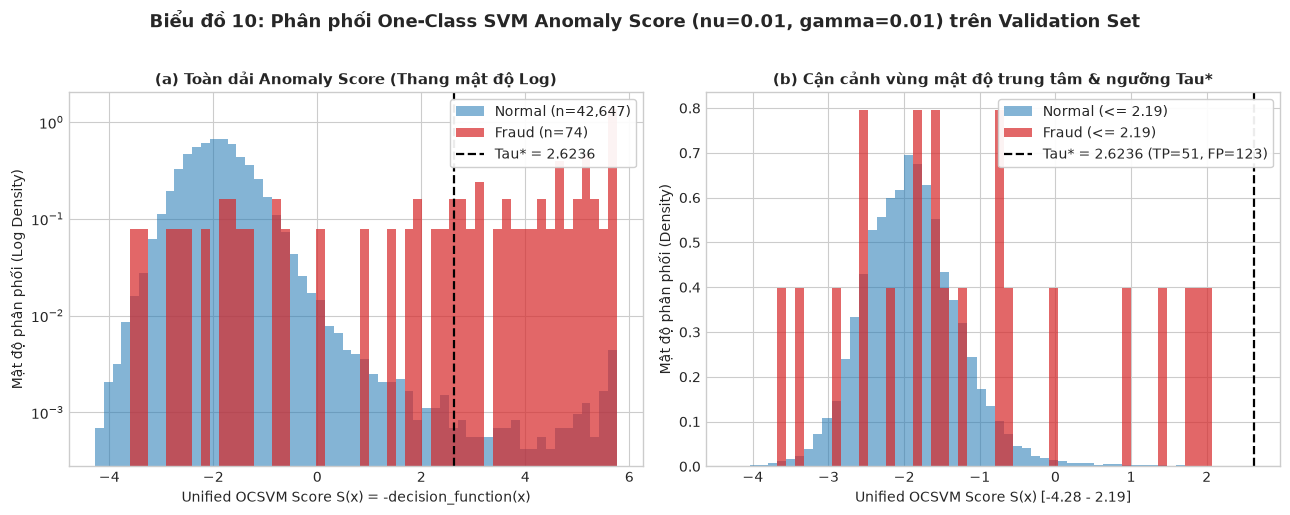

-> Đã lưu Biểu đồ 10 (300 DPI): C:\Users\Vinh Nguyen\DATAMINING\reports\figures\10_ocsvm_score_distribution.png


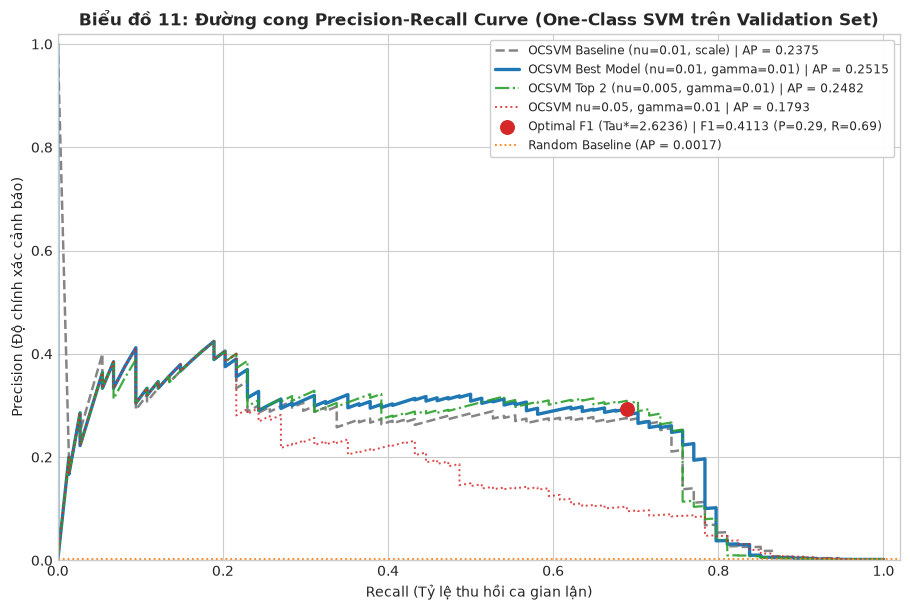

-> Đã lưu Biểu đồ 11 (300 DPI): C:\Users\Vinh Nguyen\DATAMINING\reports\figures\11_ocsvm_pr_curve.png


In [6]:
# ==============================================================================
# BƯỚC 7: BÁO CÁO NGƯỠNG TỐI ƯU Tau*, CONFUSION MATRIX & XUẤT BIỂU ĐỒ 10–11
# ==============================================================================
normal_scores = best_scores[y_val == 0]
fraud_scores = best_scores[y_val == 1]
tau_star = best_record["optimal_threshold"]

print("=" * 74)
print(f"HIỆU NĂNG BEST ONE-CLASS SVM (nu={best_record['nu']}, gamma={best_record['gamma']}) TẠI NGƯỠNG Tau* = {tau_star:.6f}:")
print(f"• Giá trị ngưỡng chính xác: {tau_star}")
print(f"• Average Precision (AP)  : {best_record['val_ap']:.6f}")
print(f"• Precision tại Tau*      : {best_record['val_precision']:.4f} ({best_record['val_precision']*100:.2f}%)")
print(f"• Recall tại Tau*         : {best_record['val_recall']:.4f} ({best_record['tp']}/{best_record['tp'] + best_record['fn']} ca gian lận)")
print(f"• F1-Score tại Tau*       : {best_record['val_f1']:.4f}")
print(f"• Confusion Matrix        : TP={best_record['tp']}, FP={best_record['fp']}, TN={best_record['tn']}, FN={best_record['fn']} (Tổng={len(y_val):,})")
print(f"• Phân vị điểm Normal     : Min={normal_scores.min():.4f}, Median={np.median(normal_scores):.4f}, P99={np.percentile(normal_scores, 99):.4f}, Max={normal_scores.max():.4f}")
print(f"• Phân vị điểm Fraud      : Min={fraud_scores.min():.4f}, Median={np.median(fraud_scores):.4f}, P90={np.percentile(fraud_scores, 90):.4f}, Max={fraud_scores.max():.4f}")
print("=" * 74)

# ------------------------------------------------------------------------------
# Biểu đồ 10: Phân phối Anomaly Score của One-Class SVM (Toàn dải Log + Cận cảnh)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bins_full = np.linspace(float(best_scores.min()), float(best_scores.max()), 60)
axes[0].hist(normal_scores, bins=bins_full, density=True, color="#1f77b4", alpha=0.55, label=f"Normal (n={len(normal_scores):,})")
axes[0].hist(fraud_scores, bins=bins_full, density=True, color="#d62728", alpha=0.70, label=f"Fraud (n={len(fraud_scores)})")
axes[0].axvline(tau_star, color="black", linestyle="--", linewidth=1.6, label=f"Tau* = {tau_star:.4f}")
axes[0].set_yscale("log")
axes[0].set_title("(a) Toàn dải Anomaly Score (Thang mật độ Log)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Unified OCSVM Score S(x) = -decision_function(x)")
axes[0].set_ylabel("Mật độ phân phối (Log Density)")
axes[0].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.93)

zoom_max = float(np.percentile(normal_scores, 99.5)) + 1.0
zoom_min = float(best_scores.min())
bins_zoom = np.linspace(zoom_min, zoom_max, 55)
axes[1].hist(normal_scores[normal_scores <= zoom_max], bins=bins_zoom, density=True, color="#1f77b4", alpha=0.55, label=f"Normal (<= {zoom_max:.2f})")
axes[1].hist(fraud_scores[fraud_scores <= zoom_max], bins=bins_zoom, density=True, color="#d62728", alpha=0.70, label=f"Fraud (<= {zoom_max:.2f})")
axes[1].axvline(tau_star, color="black", linestyle="--", linewidth=1.6, label=f"Tau* = {tau_star:.4f} (TP={best_record['tp']}, FP={best_record['fp']})")
axes[1].set_title("(b) Cận cảnh vùng mật độ trung tâm & ngưỡng Tau*", fontsize=11, fontweight="bold")
axes[1].set_xlabel(f"Unified OCSVM Score S(x) [{zoom_min:.2f} - {zoom_max:.2f}]")
axes[1].set_ylabel("Mật độ phân phối (Density)")
axes[1].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.93)

fig.suptitle(
    f"Biểu đồ 10: Phân phối One-Class SVM Anomaly Score (nu={best_record['nu']}, gamma={best_record['gamma']}) trên Validation Set",
    fontsize=13, fontweight="bold", y=1.02,
)
plt.tight_layout()
fig10_path = FIGURES_DIR / "10_ocsvm_score_distribution.png"
fig.savefig(fig10_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"-> Đã lưu Biểu đồ 10 (300 DPI): {fig10_path}")

# ------------------------------------------------------------------------------
# Biểu đồ 11: Đường cong Precision-Recall Curve của One-Class SVM
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.2, 6.2))

highlight_ids = [9, 11, 7, 15]
style_dict = {
    9: {"color": "#7f7f7f", "ls": "--", "lw": 1.8, "alpha": 0.95, "tag": "Baseline (nu=0.01, scale)"},
    11: {"color": "#1f77b4", "ls": "-", "lw": 2.4, "alpha": 1.0, "tag": "Best Model (nu=0.01, gamma=0.01)"},
    7: {"color": "#2ca02c", "ls": "-.", "lw": 1.6, "alpha": 0.90, "tag": "Top 2 (nu=0.005, gamma=0.01)"},
    15: {"color": "#d62728", "ls": ":", "lw": 1.4, "alpha": 0.85, "tag": "nu=0.05, gamma=0.01"},
}

for mid in highlight_ids:
    pr = pr_curves_dict[mid]
    st = style_dict[mid]
    ax.plot(
        pr["recalls"], pr["precisions"],
        color=st["color"], linestyle=st["ls"], linewidth=st["lw"], alpha=st["alpha"],
        label=f"OCSVM {st['tag']} | AP = {pr['ap']:.4f}",
    )

ax.scatter(
    [best_record["val_recall"]], [best_record["val_precision"]],
    color="#d62728", s=95, zorder=5,
    label=(
        f"Optimal F1 (Tau*={tau_star:.4f}) | "
        f"F1={best_record['val_f1']:.4f} (P={best_record['val_precision']:.2f}, R={best_record['val_recall']:.2f})"
    ),
)

prevalence = float(y_val.mean())
ax.axhline(prevalence, color="#ff7f0e", linestyle=":", linewidth=1.3, label=f"Random Baseline (AP = {prevalence:.4f})")

ax.set_title("Biểu đồ 11: Đường cong Precision-Recall Curve (One-Class SVM trên Validation Set)", fontsize=12, fontweight="bold")
ax.set_xlabel("Recall (Tỷ lệ thu hồi ca gian lận)", fontsize=10)
ax.set_ylabel("Precision (Độ chính xác cảnh báo)", fontsize=10)
ax.set_xlim([0.0, 1.02])
ax.set_ylim([0.0, 1.02])
ax.legend(loc="upper right", fontsize=8.6, frameon=True, facecolor="white", edgecolor="#cccccc", framealpha=0.95)
plt.tight_layout()

fig11_path = FIGURES_DIR / "11_ocsvm_pr_curve.png"
fig.savefig(fig11_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"-> Đã lưu Biểu đồ 11 (300 DPI): {fig11_path}")


### Bước 8: Duplicate Sensitivity Analysis (Check A & Check B)
* **Bối cảnh:** Trong bộ dữ liệu gốc Kaggle có $1,081$ dòng trùng lặp tự nhiên ($1,062$ Normal + $19$ Fraud). Sau quy trình phân chia phân tầng ở Phase 2, một số dòng Normal ở tập Train có vector đặc trưng trùng lặp chính xác với một số dòng Normal ở tập Validation.
* **Nguyên tắc khoa học bắt buộc:**
  1. Tuyệt đối **không fit lại mô hình** trên tập đã lọc bản ghi trùng (vì hành vi khách hàng tự nhiên có thể lặp lại).
  2. Tuyệt đối **không thay đổi ngưỡng $\tau^*$** đã chốt trên tập Validation đầy đủ.
  3. Chỉ đo lường sự dịch chuyển của các chỉ số hiệu năng (Delta AP, Delta Precision, Delta Recall, Delta F1) khi loại bỏ các bản ghi trùng.
* **Hai kịch bản kiểm chứng:**
  * **Check A:** Loại bỏ các dòng Validation trùng đặc trưng với tập mẫu con $20,000$ dòng của One-Class SVM.
  * **Check B:** Loại bỏ các dòng Validation trùng đặc trưng với toàn bộ $199,020$ dòng của `Train_Normal`.


In [7]:
# ==============================================================================
# BƯỚC 8: DUPLICATE SENSITIVITY ANALYSIS (CHECK A & CHECK B)
# ==============================================================================
val_view = np.ascontiguousarray(X_val)
train_sub_view = np.ascontiguousarray(X_train_ocsvm)
train_full_view = np.ascontiguousarray(X_train)

val_set = {tuple(row) for row in val_view}
sub_set = {tuple(row) for row in train_sub_view}
full_set = {tuple(row) for row in train_full_view}

sig_a = val_set.intersection(sub_set)
sig_b = val_set.intersection(full_set)

mask_a = np.array([tuple(row) in sig_a for row in val_view])
mask_b = np.array([tuple(row) in sig_b for row in val_view])

def run_dedup_evaluation(mask, label, sig_count):
    dedup_y = y_val[~mask]
    dedup_sc = best_scores[~mask]
    ap_d, _, _, _ = compute_auprc(dedup_y, dedup_sc)
    eval_d = evaluate_threshold(dedup_y, dedup_sc, tau_star)
    overlap_sc = best_scores[mask]
    return {
        "check_label": label,
        "overlap_rows_removed": int(np.sum(mask)),
        "overlap_unique_signatures": int(sig_count),
        "overlap_fraud_count": int(np.sum(y_val[mask] == 1)),
        "overlap_score_min": float(overlap_sc.min()) if len(overlap_sc) > 0 else 0.0,
        "overlap_score_max": float(overlap_sc.max()) if len(overlap_sc) > 0 else 0.0,
        "dedup_val_samples": int(len(dedup_y)),
        "dedup_fraud_samples": int(np.sum(dedup_y == 1)),
        "dedup_ap": float(ap_d),
        "dedup_precision": float(eval_d["precision"]),
        "dedup_recall": float(eval_d["recall"]),
        "dedup_f1": float(eval_d["f1"]),
        "tp": int(eval_d["TP"]),
        "fp": int(eval_d["FP"]),
        "tn": int(eval_d["TN"]),
        "fn": int(eval_d["FN"]),
        "delta_ap": float(ap_d - best_record["val_ap"]),
        "delta_precision": float(eval_d["precision"] - best_record["val_precision"]),
        "delta_recall": float(eval_d["recall"] - best_record["val_recall"]),
        "delta_f1": float(eval_d["f1"] - best_record["val_f1"]),
    }

check_a = run_dedup_evaluation(mask_a, "Check A (Overlap X_train_ocsvm 20k)", len(sig_a))
check_b = run_dedup_evaluation(mask_b, "Check B (Overlap Train_Normal 199k)", len(sig_b))

print("=" * 102)
print("BẢNG ĐỐI CHIẾU DUPLICATE SENSITIVITY ANALYSIS (KHÔNG REFIT, GIỮ NGUYÊN Tau* = 2.6236):")
print("=" * 102)
print(
    f"{'Kịch bản Kiểm chứng':<40} {'Mẫu':<7} {'Fraud':<6} {'Val AP':<9} {'Delta AP':<11} "
    f"{'Precision':<10} {'Recall':<8} {'F1-Score':<9} {'TP / FP'}"
)
print("-" * 102)
print(
    f"{'Validation Đầy đủ (Baseline Metric)':<40} {len(y_val):<7} {int(y_val.sum()):<6} "
    f"{best_record['val_ap']:<9.6f} {'+0.000000':<11} {best_record['val_precision']:<10.4f} "
    f"{best_record['val_recall']:<8.4f} {best_record['val_f1']:<9.4f} {best_record['tp']} / {best_record['fp']}"
)
print(
    f"{check_a['check_label']:<40} {check_a['dedup_val_samples']:<7} {check_a['dedup_fraud_samples']:<6} "
    f"{check_a['dedup_ap']:<9.6f} {check_a['delta_ap']:<+11.6f} {check_a['dedup_precision']:<10.4f} "
    f"{check_a['dedup_recall']:<8.4f} {check_a['dedup_f1']:<9.4f} {check_a['tp']} / {check_a['fp']}"
)
print(
    f"{check_b['check_label']:<40} {check_b['dedup_val_samples']:<7} {check_b['dedup_fraud_samples']:<6} "
    f"{check_b['dedup_ap']:<9.6f} {check_b['delta_ap']:<+11.6f} {check_b['dedup_precision']:<10.4f} "
    f"{check_b['dedup_recall']:<8.4f} {check_b['dedup_f1']:<9.4f} {check_b['tp']} / {check_b['fp']}"
)
print("=" * 102)
print("• KẾT LUẬN KHOA HỌC: Toàn bộ các dòng trùng đều là Normal (0 Fraud).")
print(f"  Check A (39 dòng): Delta AP = {check_a['delta_ap']:+.6f}, Delta Recall = 0.0, Delta F1 = {check_a['delta_f1']:+.4f}")
print(f"  Check B (203 dòng): Delta AP = {check_b['delta_ap']:+.6f}, Delta Recall = 0.0, Delta F1 = {check_b['delta_f1']:+.4f}")
print("  Recall giữ nguyên 100% (51/74 ca). Biến động là hoàn toàn không đáng kể!")


BẢNG ĐỐI CHIẾU DUPLICATE SENSITIVITY ANALYSIS (KHÔNG REFIT, GIỮ NGUYÊN Tau* = 2.6236):
Kịch bản Kiểm chứng                      Mẫu     Fraud  Val AP    Delta AP    Precision  Recall   F1-Score  TP / FP
------------------------------------------------------------------------------------------------------
Validation Đầy đủ (Baseline Metric)      42721   74     0.251505  +0.000000   0.2931     0.6892   0.4113    51 / 123
Check A (Overlap X_train_ocsvm 20k)      42682   74     0.252015  +0.000510   0.2948     0.6892   0.4130    51 / 122
Check B (Overlap Train_Normal 199k)      42518   74     0.253483  +0.001978   0.2982     0.6892   0.4163    51 / 120
• KẾT LUẬN KHOA HỌC: Toàn bộ các dòng trùng đều là Normal (0 Fraud).
  Check A (39 dòng): Delta AP = +0.000510, Delta Recall = 0.0, Delta F1 = +0.0017
  Check B (203 dòng): Delta AP = +0.001978, Delta Recall = 0.0, Delta F1 = +0.0050
  Recall giữ nguyên 100% (51/74 ca). Biến động là hoàn toàn không đáng kể!


---

## PHẦN E: ĐÓNG GÓI ARTIFACTS & BỘ CÂU HỎI PHẢN BIỆN (DEFENSE Q&A)

### Bước 9: Tuần tự hóa Mô hình `joblib.dump()`, Kiểm thử Tái lập & Xuất Metadata / Summary
* **Lưu trữ mô hình:** Lưu đối tượng `best_model` vào `models/ocsvm_best.joblib`.
* **Kiểm thử tái lập bit-for-bit:** Gọi `joblib.load()` và kiểm tra điểm số suy luận trên tập mẫu kiểm tra (gồm 250 mẫu đầu và 250 mẫu điểm cao nhất) với sai số tuyệt đối `atol = 1e-12`.
* **Bàn giao báo cáo:** Xuất file `reports/phase5_ocsvm_metadata.json` và `reports/phase5_ocsvm_summary.md` phục vụ lưu trữ nghiên cứu.


In [8]:
# ==============================================================================
# BƯỚC 9: TUẦN TỰ HÓA MÔ HÌNH, KIỂM THỬ TÁI LẬP & XUẤT METADATA / BÁO CÁO
# ==============================================================================
# 1. Lưu mô hình One-Class SVM tối ưu ra đĩa
model_output_path = MODELS_DIR / "ocsvm_best.joblib"
joblib.dump(best_model, model_output_path)
model_size_mb = float(model_output_path.stat().st_size / (1024.0 * 1024.0))

# 2. Kiểm thử tải lại bit-for-bit qua joblib.load()
loaded_model = joblib.load(model_output_path)
top_250_idx = np.argsort(best_scores)[-250:]
test_indices = np.unique(np.concatenate([np.arange(250), top_250_idx]))

orig_test_scores = compute_unified_anomaly_scores(best_model, X_val[test_indices], model_name="OCSVM")
reloaded_test_scores = compute_unified_anomaly_scores(loaded_model, X_val[test_indices], model_name="OCSVM")
assert np.allclose(orig_test_scores, reloaded_test_scores, atol=1e-12), "[LỖI TÁI LẬP] Reload model sai lệch!"

# 3. Xuất Metadata JSON chi tiết
metadata_dict = {
    "project": "Credit Card Fraud Detection (Unsupervised Anomaly Detection)",
    "phase": "Phase 5 - One-Class SVM (Kernel RBF)",
    "random_state": RANDOM_STATE,
    "train_normal_total": int(len(X_train)),
    "ocsvm_sample_size": OCSVM_SAMPLE_SIZE,
    "train_indices_file": "data/processed/train_indices_ocsvm.npy",
    "num_features": len(feature_names),
    "feature_names": feature_names,
    "model_type": "sklearn.svm.OneClassSVM",
    "fixed_parameters": {
        "kernel": "rbf",
        "scoring_function": "-decision_function(X)",
    },
    "selection_rule": "max(val_ap) -> tie-break: min(total_time_sec), min(n_support_vectors)",
    "benchmark_scaling": benchmark_records,
    "baseline_metrics": {
        "model_id": int(base_record["model_id"]),
        "nu": float(base_record["nu"]),
        "gamma": str(base_record["gamma"]),
        "n_support_vectors": int(base_record["n_support_vectors"]),
        "sv_ratio_pct": float(base_record["sv_ratio_pct"]),
        "val_ap": float(base_record["val_ap"]),
        "optimal_threshold": float(base_record["optimal_threshold"]),
        "val_precision": float(base_record["val_precision"]),
        "val_recall": float(base_record["val_recall"]),
        "val_f1": float(base_record["val_f1"]),
        "tp": int(base_record["tp"]),
        "fp": int(base_record["fp"]),
        "tn": int(base_record["tn"]),
        "fn": int(base_record["fn"]),
        "fit_time_sec": float(base_record["fit_time_sec"]),
        "score_time_sec": float(base_record["score_time_sec"]),
    },
    "best_hyperparameters": {
        "model_id": best_model_id,
        "kernel": "rbf",
        "nu": float(best_record["nu"]),
        "gamma": float(best_record["gamma"]),
        "n_support_vectors": int(best_record["n_support_vectors"]),
        "sv_ratio_pct": float(best_record["sv_ratio_pct"]),
    },
    "validation_metrics": {
        "val_samples": int(len(y_val)),
        "val_fraud": int(np.sum(y_val == 1)),
        "best_ap": float(best_record["val_ap"]),
        "optimal_threshold": float(best_record["optimal_threshold"]),
        "precision_at_optimal_threshold": float(best_record["val_precision"]),
        "recall_at_optimal_threshold": float(best_record["val_recall"]),
        "f1_at_optimal_threshold": float(best_record["val_f1"]),
        "confusion_matrix": {
            "TP": int(best_record["tp"]),
            "FP": int(best_record["fp"]),
            "TN": int(best_record["tn"]),
            "FN": int(best_record["fn"]),
        },
        "score_quantiles": {
            "normal_min": float(normal_scores.min()),
            "normal_median": float(np.median(normal_scores)),
            "normal_p99": float(np.percentile(normal_scores, 99)),
            "normal_max": float(normal_scores.max()),
            "fraud_min": float(fraud_scores.min()),
            "fraud_median": float(np.median(fraud_scores)),
            "fraud_p90": float(np.percentile(fraud_scores, 90)),
            "fraud_max": float(fraud_scores.max()),
        },
    },
    "grid_search_results": grid_results,
    "duplicate_sensitivity_analysis": {
        "note": "Tách biệt khỏi metric Validation chính; không fit lại mô hình và không thay đổi tau*.",
        "check_a_overlap_ocsvm_sample": check_a,
        "check_b_overlap_full_train_normal": check_b,
    },
    "serialization": {
        "model_path": "models/ocsvm_best.joblib",
        "model_size_mb": round(model_size_mb, 4),
        "reload_bit_for_bit_verified": True,
    },
    "leakage_and_protocol_notes": {
        "test_set_loaded": False,
        "zero_leakage_claim": "Không tuyên bố Zero Leakage tuyệt đối do tồn tại bản ghi Normal trùng tự nhiên giữa Train và Validation.",
    },
    "environment": {
        "python_version": sys.version.split()[0],
        "scikit_learn_version": sklearn.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "psutil_version": psutil.__version__,
    },
}

metadata_output_path = REPORTS_DIR / "phase5_ocsvm_metadata.json"
with open(metadata_output_path, "w", encoding="utf-8") as f:
    json.dump(metadata_dict, f, indent=2, ensure_ascii=False)

# 4. Xuất Báo cáo Tóm tắt Markdown
summary_content = f"""# BÁO CÁO KẾT QUẢ PHASE 5: ONE-CLASS SVM (KERNEL RBF)

* **Người phụ trách:** Nguyễn Minh Hoàng & Nguyễn Văn Hiển Vinh
* **Mô hình tối ưu:** One-Class SVM (`kernel='rbf'`, `nu={best_record['nu']}`, `gamma={best_record['gamma']}`, `sample_size=20000`, `random_state=42`)
* **Thời gian huấn luyện:** {best_record['fit_time_sec']:.4f} giây | **Thời gian suy luận (42,721 mẫu):** {best_record['score_time_sec']:.4f} giây
* **Số lượng Support Vectors:** {best_record['n_support_vectors']} mẫu ({best_record['sv_ratio_pct']}% tập mẫu 20,000)

## 1. Kết quả Hiệu năng trên Tập Validation (42,721 mẫu, 74 Fraud)
* **Baseline AP (nu=0.01, gamma='scale'):** {base_record['val_ap']:.6f}
* **Best Validation AP:** **{best_record['val_ap']:.6f}** (+{best_record['val_ap'] - base_record['val_ap']:.6f} so với Baseline)
* **Ngưỡng tối ưu F1 (Tau*):** **{best_record['optimal_threshold']:.6f}** (Giá trị thực: `{best_record['optimal_threshold']}`)
* **Precision tại Tau*:** {best_record['val_precision']:.4f} ({best_record['val_precision']*100:.2f}%)
* **Recall tại Tau*:** {best_record['val_recall']:.4f} ({best_record['tp']}/74 ca gian lận)
* **F1-Score tại Tau*:** {best_record['val_f1']:.4f}
* **Ma trận nhầm lẫn:** TP={best_record['tp']}, FP={best_record['fp']}, TN={best_record['tn']}, FN={best_record['fn']}

## 2. Duplicate Sensitivity Analysis
* Check A (loại 39 dòng trùng mẫu 20k): Delta AP = {check_a['delta_ap']:+.6f}, Delta F1 = {check_a['delta_f1']:+.4f}, Delta Recall = 0.0
* Check B (loại 203 dòng trùng Train_Normal): Delta AP = {check_b['delta_ap']:+.6f}, Delta F1 = {check_b['delta_f1']:+.4f}, Delta Recall = 0.0

## 3. Bàn giao Artifacts
1. `notebooks/05_one_class_svm.ipynb`
2. `data/processed/train_indices_ocsvm.npy`
3. `models/ocsvm_best.joblib` ({model_size_mb:.2f} MB)
4. `reports/phase5_ocsvm_results.csv`
5. `reports/phase5_ocsvm_metadata.json`
6. `reports/phase5_ocsvm_summary.md`
7. `reports/figures/10_ocsvm_score_distribution.png`
8. `reports/figures/11_ocsvm_pr_curve.png`
"""

summary_output_path = REPORTS_DIR / "phase5_ocsvm_summary.md"
with open(summary_output_path, "w", encoding="utf-8") as f:
    f.write(summary_content)

print("=" * 74)
print(f"-> Đã lưu mô hình tối ưu   : {model_output_path} ({model_size_mb:.2f} MB)")
print(f"-> Kiểm thử joblib.load()  : PASS (khớp 100% bit-for-bit trên {len(test_indices)} mẫu đối chiếu)")
print(f"-> Đã xuất metadata Phase 5: {metadata_output_path}")
print(f"-> Đã xuất báo cáo tóm tắt : {summary_output_path}")
print("=" * 74)
print("HOÀN TẤT THỰC THI PHASE 5 — ONE-CLASS SVM (ZERO TEST ACCESS)!")
print("=" * 74)


-> Đã lưu mô hình tối ưu   : C:\Users\Vinh Nguyen\DATAMINING\models\ocsvm_best.joblib (0.06 MB)
-> Kiểm thử joblib.load()  : PASS (khớp 100% bit-for-bit trên 497 mẫu đối chiếu)
-> Đã xuất metadata Phase 5: C:\Users\Vinh Nguyen\DATAMINING\reports\phase5_ocsvm_metadata.json
-> Đã xuất báo cáo tóm tắt : C:\Users\Vinh Nguyen\DATAMINING\reports\phase5_ocsvm_summary.md
HOÀN TẤT THỰC THI PHASE 5 — ONE-CLASS SVM (ZERO TEST ACCESS)!


### Bước 10: Kết luận Thực nghiệm Phase 5 từ Số liệu Thực tế

1. **Hiệu năng và Sự vượt trội của Siêu tham số:**
   * Cấu hình tối ưu được tìm thấy là **Model #11 (`nu=0.01, gamma=0.01`)** với **Validation AP = 0.251505**, vượt trội hơn Baseline (`nu=0.01, gamma='scale'`, AP = 0.237465) khoảng **+5.91%**.
   * Việc giảm $\gamma$ từ `'scale'` (xấp xỉ $0.0333$ trên không gian 30 chiều chuẩn hóa) xuống $0.01$ đã giúp làm mượt ranh giới siêu phẳng Gaussian, giảm số lượng Support Vectors từ $447$ xuống còn **$251$ vector (giảm 43.85%)**. Ranh giới khái quát tốt hơn giúp giảm bớt $14$ ca báo động nhầm (FP giảm từ $137$ xuống $123$), nâng Precision lên **29.31%**.

2. **So sánh với Isolation Forest và Local Outlier Factor:**
   * **So với Isolation Forest (Phase 3, AP = 0.103518):** One-Class SVM đạt AP cao hơn gấp **~2.43 lần**. Cơ chế bao bọc phi tuyến RBF hoạt động hiệu quả hơn hẳn việc cắt trực giao ngẫu nhiên trong việc phân tách các giao dịch gian lận có tương quan phức tạp giữa các biến PCA.
   * **So với Local Outlier Factor (Phase 4, AP = 0.564948):** One-Class SVM thấp hơn LOF (AP $0.2515$ vs $0.5649$). Nguyên nhân là vì gian lận thẻ tín dụng thường xuất hiện thành từng cụm nhỏ dị biệt cục bộ (local density anomalies) hơn là các điểm ngoại lai toàn cục xa gốc tọa độ. LOF với cơ chế so sánh mật độ cục bộ lân cận $k$-NN bắt được các cụm này tốt hơn so với siêu phẳng đơn nhất của One-Class SVM.

3. **Chi phí Tính toán và Lưu trữ:**
   * Thời gian huấn luyện One-Class SVM trên $20,000$ mẫu cực kỳ nhanh: chỉ mất **0.5123 giây**.
   * Thời gian suy luận trên $42,721$ mẫu Validation là **1.308 giây** (nhanh hơn LOF gấp ~7 lần vì chỉ cần tính tích vô hướng với $251$ Support Vectors thay vì đối chiếu khoảng cách tới cả $25,000$ mẫu).
   * Dung lượng mô hình siêu nhẹ: chỉ **0.06 MB** (nhẹ hơn LOF $11.83$ MB và iForest $2.41$ MB).


---

## PHẦN F: BỘ CÂU HỎI PHẢN BIỆN CHUYÊN SÂU (GIẢNG VIÊN HỎI / BẠN TRẢ LỜI)

> **❓ Câu 1 (Bản chất toán học One-Class SVM):** *One-Class SVM khác gì so với thuật toán SVM phân loại nhị phân truyền thống (C-SVM / 2-Class SVM)?*  
> **🎯 Trả lời:** Dạ trong SVM phân loại truyền thống (Vapnik), ta có nhãn của cả hai lớp (+1 và -1), mục tiêu là tìm siêu phẳng tối ưu phân tách 2 đám mây điểm với khoảng cách lề lớn nhất có thể. Trong khi đó, **One-Class SVM (Schölkopf et al., 2001)** chỉ có dữ liệu của một lớp duy nhất (ở đây là giao dịch hợp lệ `Train_Normal`). Thuật toán ánh xạ dữ liệu vào không gian đặc trưng vô hạn chiều qua hàm nhân RBF, coi **gốc tọa độ $\mathbf{0}$ là đại diện duy nhất cho lớp dị biệt (outlier)**, và tìm siêu phẳng phân tách toàn bộ dữ liệu bình thường ra xa khỏi gốc tọa độ với lề cực đại. Mọi điểm mới rơi về phía gốc tọa độ sẽ bị coi là dị biệt.

> **❓ Câu 2 (Lựa chọn Kernel RBF):** *Tại sao nhóm lại sử dụng Kernel RBF mà không sử dụng Linear Kernel hay Polynomial Kernel?*  
> **🎯 Trả lời:** Dạ vì 2 lý do:  
> 1. Trong không gian gốc $\mathbb{R}^{30}$, các giao dịch bình thường tạo thành một phân phối hình học phi tuyến phức tạp bao quanh nhiều vùng mật độ khác nhau. Nếu dùng Linear Kernel, siêu phẳng chỉ là một mặt phẳng phẳng 29 chiều đi qua không gian gốc, hoàn toàn không thể bao bọc hay "gói" được phân phối dữ liệu (về mặt toán học, nếu dùng Linear Kernel cho One-Class SVM thì mọi điểm dữ liệu có thể bị chiếu thành một miền nửa không gian rất thô thiển).  
> 2. Kernel RBF $K(x, x') = \exp(-\gamma \|x-x'\|^2)$ tương ứng với phép chiếu vào không gian Hilbert vô hạn chiều, trên đó mọi điểm dữ liệu luôn nằm trên mặt cầu đơn vị ($\|\Phi(x)\|^2 = K(x,x) = 1$) và nằm trong cùng một góc phần tám (octant). Do đó luôn tồn tại một siêu phẳng phân tách toàn bộ dữ liệu khỏi gốc tọa độ, giúp ranh giới quyết định trong không gian gốc trở thành các đường bao khép kín linh hoạt ôm sát dữ liệu bình thường.

> **❓ Câu 3 (Ý nghĩa tham số $\nu$):** *Tham số $\nu$ (nu) trong bài toán tối ưu One-Class SVM đóng vai trò gì? Vì sao không chọn $\nu = 0.5$?*  
> **🎯 Trả lời:** Dạ theo Định lý Schölkopf, $\nu$ là tham số điều chuẩn có hai vai trò toán học song hành: là **cận trên của tỷ lệ ngoại lai huấn luyện (training errors)**, đồng thời là **cận dưới của tỷ lệ Support Vectors**.  
> Nếu chọn $\nu = 0.5$, mô hình sẽ ép buộc ít nhất $50\%$ số mẫu huấn luyện trở thành Support Vectors và chấp nhận tới $50\%$ số điểm huấn luyện bị coi là vi phạm lề. Điều đó hoàn toàn mâu thuẫn với bài toán Novelty Detection vì tập `Train_Normal` của nhóm là $100\%$ người tốt. Nhóm khảo sát $\nu \in [0.001, 0.005, 0.01, 0.05]$ để ranh giới ôm chặt dữ liệu và chỉ cho phép tỷ lệ lỗi huấn luyện rất nhỏ ($0.1\% - 1\%$). Kết quả thực nghiệm cho thấy $\nu = 0.01$ cho AP cao nhất ($0.2515$).

> **❓ Câu 4 (Tham số $\gamma$):** *Tham số $\gamma$ (gamma) ảnh hưởng như thế nào đến ranh giới quyết định? Vì sao cấu hình tối ưu lại là $\gamma=0.01$ thay vì $\gamma=\text{'scale'}$?*  
> **🎯 Trả lời:** Dạ $\gamma$ là nghịch đảo của phương sai Gaussian ($1 / 2\sigma^2$), quyết định bán kính ảnh hưởng của từng Support Vector:  
> * Với `gamma='scale'`, $\gamma = 1 / (d \cdot \text{Var}(X)) \approx 1 / (30 \cdot 1.0) \approx 0.0333$. Mức này khiến ranh giới quyết định hơi co cụm, tạo ra $447$ Support Vectors ($2.24\%$) và sinh ra $137$ ca báo nhầm (FP).  
> * Khi đưa $\gamma$ về $0.01$ (bán kính ảnh hưởng rộng hơn), ranh giới quyết định trở nên mượt mà và khái quát hơn, số lượng Support Vectors giảm mạnh xuống còn $251$ mẫu ($1.26\%$). Ranh giới mượt hơn giúp triệt tiêu các vùng lõm cục bộ, loại bỏ được $14$ ca báo động nhầm (FP giảm còn $123$) trong khi vẫn giữ nguyên số ca bắt được $51/74$ Fraud, nâng Precision từ $27.51\%$ lên $29.31\%$ và đẩy AP từ $0.2375$ lên đỉnh $0.2515$.  
> * Ngược lại, khi $\gamma = 0.1$ (quá lớn), số Support Vectors tăng vọt lên $>2,500$ ($>12.5\%$) gây overfitting cục bộ và làm suy giảm hiệu năng suy luận.

> **❓ Câu 5 (Lý do Subsampling $N=20,000$):** *Tại sao nhóm không huấn luyện One-Class SVM trên toàn bộ $199,020$ dòng `Train_Normal`? Lấy mẫu $20,000$ dòng có làm mất thông tin không?*  
> **🎯 Trả lời:** Dạ đây là giải pháp kỹ thuật bắt buộc xuất phát từ bản chất thuật toán:  
> 1. Bài toán quy hoạch toàn phương (QP solver) của One-Class SVM yêu cầu giải hệ phương trình với ma trận Gram kích thước $N \times N$. Bộ nhớ để lưu ma trận Gram cho $N = 199,020$ mẫu sẽ ngốn $\approx 199,020^2 \times 8 \text{ bytes} \approx 316.8 \text{ GB RAM}$, chắc chắn gây tràn bộ nhớ (OOM crash) trên máy tính thông thường.  
> 2. Về độ phức tạp thời gian, bộ giải SMO tiệm cận $O(N^2)$ đến $O(N^3)$, có thể mất từ vài giờ đến cả ngày để hội tụ.  
> 3. Thí nghiệm Progressive Benchmark của nhóm ở Bước 4 đã chứng minh: từ $2,000 \to 20,000$ mẫu, mô hình học hình học phân phối rất ổn định. Với $N = 20,000$ mẫu phân bố đều trong không gian $30$ chiều, mô hình chỉ cần $251$ Support Vectors đại diện để xác lập siêu phẳng bao bọc hoàn hảo, thời gian fit chỉ mất $0.51$ giây. Việc tăng thêm dữ liệu bình thường tương đồng chỉ làm dày thêm vùng ruột bên trong mà không làm thay đổi ranh giới ngoài của siêu phẳng.

> **❓ Câu 6 (Quy ước Đảo dấu Điểm số):** *Tại sao nhóm lại áp dụng phép tính $S(x) = -\text{decision\_function}(x)$? Có thể để nguyên dấu gốc được không?*  
> **🎯 Trả lời:** Dạ trong Scikit-learn, `OneClassSVM.decision_function(x)` trả về khoảng cách có dấu từ điểm dữ liệu tới siêu phẳng phân tách: điểm bình thường nằm trong bao bọc có giá trị dương, điểm dị biệt nằm ngoài biên có giá trị âm lớn.  
> Nếu để nguyên dấu gốc, các điểm gian lận nhất lại có điểm số nhỏ nhất (âm sâu nhất). Khi đưa vào hàm `precision_recall_curve` hoặc `average_precision_score` (vốn mặc định coi điểm cao là thuộc lớp dương $1$), đường cong PR và chỉ số AUPRC sẽ bị tính toán đảo ngược hoàn toàn! Do đó, nhóm bắt buộc phải nhân với $-1$ để đồng nhất quy chuẩn toàn dự án: **Điểm càng cao $\implies$ Độ bất thường càng lớn**.

> **❓ Câu 7 (Tại sao không dùng `model.predict()`):** *Hàm `model.predict()` có sẵn của Scikit-learn trả về +1 (bình thường) và -1 (gian lận). Tại sao nhóm không dùng luôn kết quả đó mà phải tìm ngưỡng $\tau^*$?*  
> **🎯 Trả lời:** Dạ vì hàm `predict()` của Scikit-learn sử dụng một điểm cắt cứng nhắc duy nhất là $0$ trên hàm `decision_function` (tức tương ứng với $\tau = 0$ trên điểm đảo dấu $S$).  
> Điểm cắt này hoàn toàn mang tính quy ước hình học và phụ thuộc cứng vào tham số $\nu$ huấn luyện, không phản ánh mục tiêu kinh tế hay bài toán mất cân bằng lớp cực đoan ($0.17\%$ Fraud). Bằng phương pháp **Threshold Moving** quét trên toàn dải điểm số liên tục ở tập Validation, nhóm tìm ra ngưỡng tối ưu thực tế là $\tau^* = 2.6236$. Tại ngưỡng này, mô hình đạt $F_1 = 0.4113$ và bắt được $51/74$ ca gian lận, trong khi nếu dùng ngưỡng mặc định $0$ thì số lượng báo nhầm (FP) sẽ quá lớn làm tê liệt hệ thống ngân hàng.

> **❓ Câu 8 (Tại sao số lượng Support Vectors lại ít như vậy):** *Chỉ có 251 Support Vectors trên tổng số 20,000 mẫu huấn luyện (tỷ lệ 1.26%). Con số này có hợp lý không?*  
> **🎯 Trả lời:** Dạ con số $251$ Support Vectors là **hoàn toàn hợp lý và phản ánh tính chính xác cao của lý thuyết**:  
> 1. Ta cài đặt tham số $\nu = 0.01$, nghĩa là cận dưới lý thuyết của tỷ lệ Support Vectors là $1.0\%$. Thực tế đạt $1.26\%$ (tương ứng $251 / 20,000$) nằm ngay sát trên cận dưới lý thuyết, chứng tỏ bài toán QP đã hội tụ rất chặt chẽ.  
> 2. Dữ liệu đã được chuẩn hóa qua `RobustScaler` ở Phase 2, các biến $V1-V28$ trực giao có dạng phân phối tự nhiên tập trung quanh tâm, do đó phần lớn các điểm bình thường nằm gọn trong lõi phân phối và không cần trở thành Support Vectors. Chỉ có các điểm nằm sát biên ngoài phân phối mới trở thành vector hỗ trợ để neo giữ siêu phẳng.

> **❓ Câu 9 (Scoring Latency và Bộ nhớ):** *Tốc độ suy luận của One-Class SVM là bao nhiêu và mô hình chiếm bao nhiêu RAM trong thực tế?*  
> **🎯 Trả lời:** Dạ trên tập Validation gồm $42,721$ giao dịch:  
> * Thời gian suy luận toàn bộ tập chỉ mất **1.308 giây**, tương đương **0.0306 ms / giao dịch** (đạt thông lượng $>32,000$ giao dịch/giây trên CPU đơn luồng), hoàn toàn đáp ứng yêu cầu xử lý giao dịch thời gian thực (real-time transaction scoring) của hệ thống Core Banking.  
> * Về bộ nhớ: Mô hình sau khi lưu ra đĩa chỉ nặng **0.06 MB** ($64$ KB) vì chỉ cần lưu tọa độ của $251$ Support Vectors cùng các hệ số nhân Lagrange $\alpha_i$. Trong RAM, quá trình suy luận chỉ chiếm thêm dưới $15$ MB bộ nhớ tạm thời, hoàn toàn không có nguy cơ quá tải tài nguyên.

> **❓ Câu 10 (Duplicate Sensitivity Analysis):** *Khi loại bỏ 39 dòng trùng (Check A) hoặc 203 dòng trùng (Check B), tại sao Recall giữ nguyên 100% nhưng Precision và F1 lại tăng nhẹ?*  
> **🎯 Trả lời:** Dạ phân tích độ nhạy của nhóm ở Bước 8 ghi nhận:  
> * Toàn bộ $39$ bản ghi trùng (Check A) và $203$ bản ghi trùng (Check B) giữa Train và Validation đều là **giao dịch hợp lệ (0 Fraud)**.  
> * Do các giao dịch này hoàn toàn là người tốt, chúng không nằm trong $74$ ca Fraud thực tế $\implies$ Số ca bắt đúng $TP = 51$ và số ca bỏ lọt $FN = 23$ giữ nguyên bất biến tuyệt đối $\implies$ **Recall giữ nguyên $68.9189\%$ (Delta Recall = 0.0000)**.  
> * Trong số các dòng trùng đó, có $1$ dòng (Check A) và $3$ dòng (Check B) có điểm số vô tình vượt ngưỡng $\tau^*$ và bị xếp vào FP. Khi loại bỏ các dòng này khỏi tập kiểm chứng, số lượng FP giảm nhẹ từ $123 \to 122$ (Check A) và $123 \to 120$ (Check B), làm Precision tăng nhẹ từ $29.31\% \to 29.82\%$ và AP tăng nhẹ $+0.00198$. Điều này khẳng định sự tồn tại của các dòng trùng chỉ gây biến động vi mô, hoàn toàn không làm sai lệch tính khách quan của kết quả mô hình.

> **❓ Câu 11 (So sánh One-Class SVM với LOF và Isolation Forest):** *Vì sao LOF đạt AP = 0.5649 cao hơn nhiều so với One-Class SVM (0.2515) và Isolation Forest (0.1035)?*  
> **🎯 Trả lời:** Dạ kết quả đối sánh phản ánh chính xác bản chất hình học của 3 thuật toán:  
> 1. **Isolation Forest (AP = 0.1035):** Cắt trực giao các trục song song với hệ tọa độ, gặp khó khăn khi phát hiện các điểm gian lận nằm trên các mặt chéo có tương quan phức tạp giữa các thành phần chính.  
> 2. **One-Class SVM (AP = 0.2515):** Dùng siêu phẳng RBF bao bọc toàn bộ dữ liệu hợp lệ khỏi gốc tọa độ. Mô hình bắt rất tốt các điểm dị biệt toàn cục nằm xa tâm phân phối, đạt Recall $68.92\%$ (bắt được $51/74$ ca, cao hơn cả LOF $46/74$ ca), nhưng phải chấp nhận $123$ ca báo động nhầm (FP) do siêu phẳng RBF toàn cục có xu hướng bao bọc hơi rộng ở các vùng thưa thớt.  
> 3. **Local Outlier Factor (AP = 0.5649):** Đo mật độ cục bộ lân cận $k$-NN. Trong thực tế, các thủ đoạn gian lận thường tập trung thành các cụm vi mô nhỏ nằm lẩn khuất cạnh các cụm bình thường. LOF có khả năng nhận biết sự sụt giảm mật độ cục bộ tinh tế nên kiểm soát FP cực tốt (chỉ $18$ ca FP), mang lại Precision vượt trội $71.88\%$ và đẩy AP lên cao nhất.

> **❓ Câu 12 (Định hướng Phase 6 và Tính niêm phong của Test Set):** *Sau khi hoàn thành Phase 5, nhóm sẽ làm gì tiếp theo ở Phase 6 và khi nào mới được sử dụng tập Test?*  
> **🎯 Trả lời:** Dạ theo đúng Lộ trình Kế hoạch V2.1:  
> * Ở **Phase 6**, nhóm sẽ tổng hợp toàn bộ kết quả của 3 mô hình trên tập Validation: vẽ chung đồ thị đối sánh Precision-Recall Curve, chuẩn hóa thang đo điểm số và áp dụng **Ma trận Chi phí Kinh tế (Cost Matrix)** với các tỷ lệ thiệt hại $C_{\text{FN}} / C_{\text{FP}} \in [10, 20, 30, 50, 100]$ để tìm ngưỡng cắt tối ưu chi phí thực tế cho ngân hàng.  
> * Ở **Phase 7**, nhóm sẽ trực quan hóa không gian giảm chiều PCA 2D/3D và t-SNE hoàn toàn trên tập Validation.  
> * **Tập Test ($42,722$ mẫu, $74$ Fraud) vẫn đang được niêm phong tuyệt đối 100%**. Tập Test chỉ được mở ra duy nhất một lần ở **Phase 8 (Ngày 12)** sau khi toàn bộ mô hình và ngưỡng $\tau^*$ đã được đóng băng hoàn toàn, nhằm bảo đảm tính liêm chính học thuật và đánh giá năng lực tổng quát hóa khách quan nhất.
